[1 2 3 4]
K 4  np.mean(ith_cluster_silhouette_values) 0.14129527474585848 str(i) 1 
K 4  np.mean(ith_cluster_silhouette_values) 0.07783335157580118 str(i) 2 
K 4  np.mean(ith_cluster_silhouette_values) 0.1463888363081999 str(i) 3 
K 4  np.mean(ith_cluster_silhouette_values) 0.19373399296731678 str(i) 4 
[1 2 3 4 5]
K 5  np.mean(ith_cluster_silhouette_values) 0.06034357383805885 str(i) 1 
K 5  np.mean(ith_cluster_silhouette_values) 0.1278481873830006 str(i) 2 
K 5  np.mean(ith_cluster_silhouette_values) 0.16887008216774813 str(i) 3 
K 5  np.mean(ith_cluster_silhouette_values) 0.1878822884483967 str(i) 4 
K 5  np.mean(ith_cluster_silhouette_values) 0.13961597212683086 str(i) 5 
[1 2 3 4 5 6]
K 6  np.mean(ith_cluster_silhouette_values) 0.13822145844839234 str(i) 1 
K 6  np.mean(ith_cluster_silhouette_values) 0.18843231272539346 str(i) 2 
K 6  np.mean(ith_cluster_silhouette_values) 0.12388078792568528 str(i) 3 
K 6  np.mean(ith_cluster_silhouette_values) 0.17080244462540092 str(i) 4 
K 6  

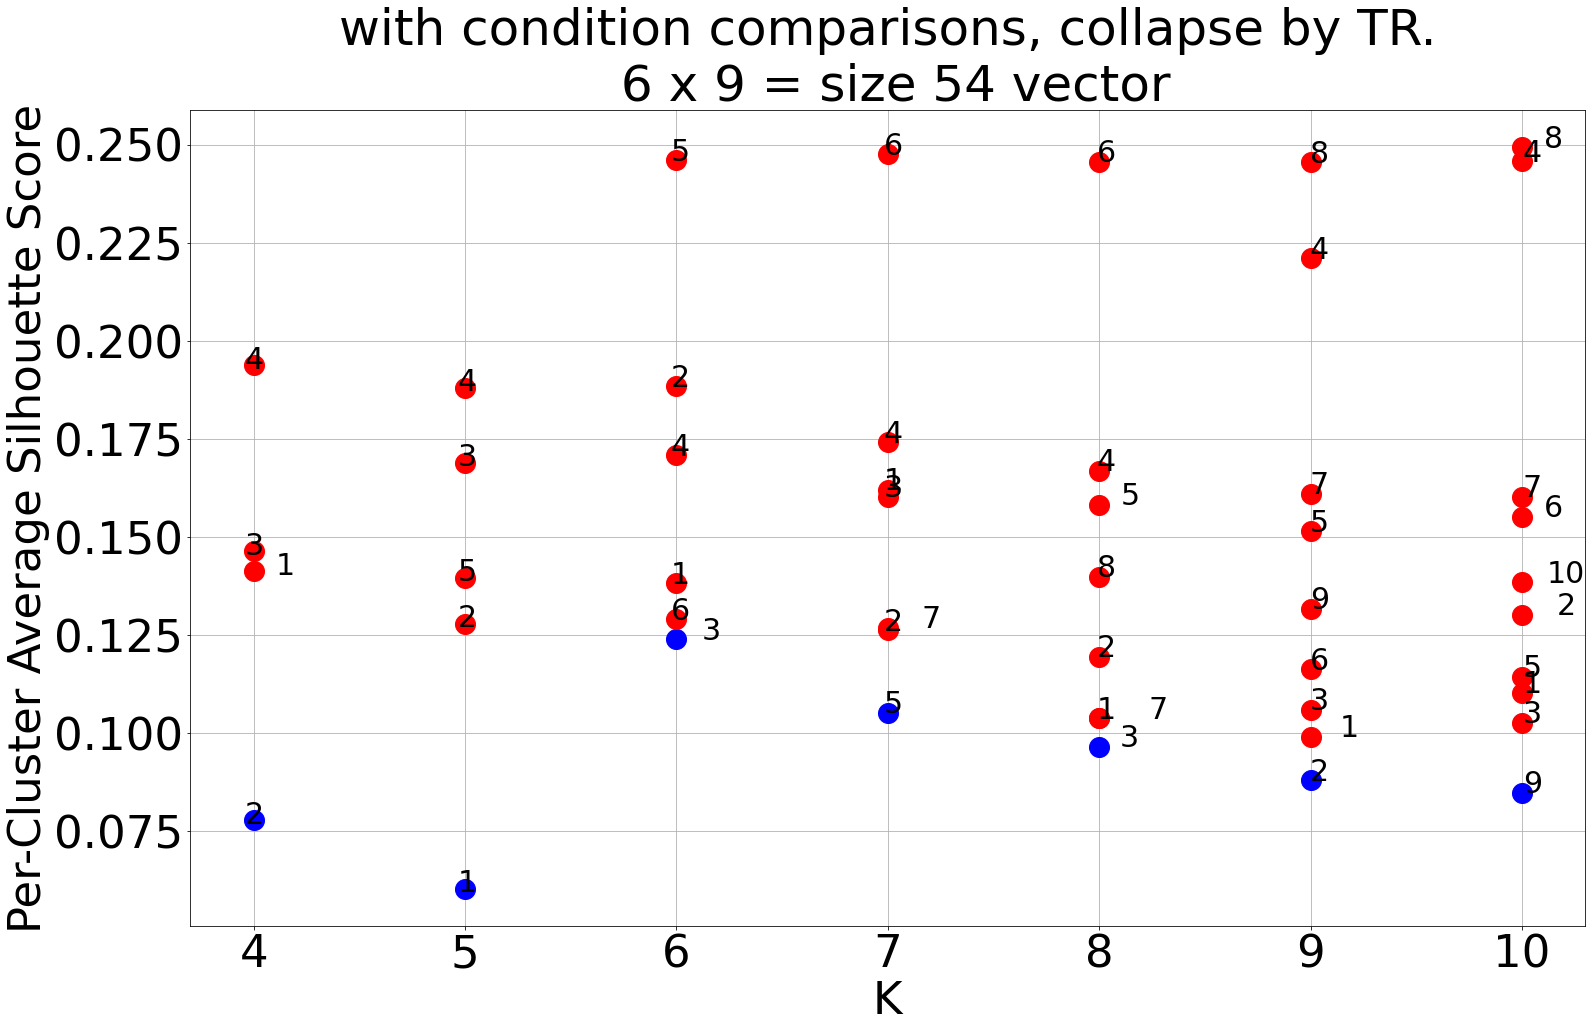

In [ ]:
import pdb
import copy
import numpy as np
import matplotlib.cm as cm
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import pyplot as plt
import matplotlib
from sklearn.metrics import silhouette_samples, silhouette_score
import nibabel as nib
from nilearn import plotting
from nilearn import image
from nilearn import datasets, surface
import numpy as np
import os
import matplotlib.font_manager
plt.rcParams.update({'font.size': 16})
from adjustText import adjust_text


fig, (ax1) = plt.subplots(1, 1)
fig.set_size_inches(25, 15)
fsize = 45
ax1.set_xticks([i for i in range(4,11)])
ax1.set_xlabel("K", fontsize = fsize)
ax1.set_ylabel("Per-Cluster Average Silhouette Score", fontsize = fsize)
ax1.tick_params(axis='x', labelsize=fsize)
ax1.tick_params(axis='y', labelsize=fsize)
texts = []
for K in range(4,11):
    in_dir = "insert path/kmeans" + str(K) + "_silhouttes_collapseTR.csv"
    labels_dir = "insert path/kmeans_" + str(K) + "clusters_collapseTR.csv"
    df = pd.read_csv(labels_dir)
    cluster_labels = np.array(df["cluster_assignment"].tolist())
    print(np.unique(cluster_labels))
    searchlight_np = np.array((df["searchlight"].tolist()))
    sample_silhouette_values = np.loadtxt(in_dir, delimiter = ",")
    n_clusters = K
    # get worst cluster index
    worst_cluster_avg = 200
    worst_cluster_i = -100
    for i in range(1,n_clusters + 1):    
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_avg = np.mean(ith_cluster_silhouette_values)
        if ith_cluster_avg < worst_cluster_avg:
            worst_cluster_avg = ith_cluster_avg
            worst_cluster_i = i
    for i in range(1,n_clusters + 1): 
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        if i == worst_cluster_i:
            ax1.plot(K,np.mean(ith_cluster_silhouette_values), 'bo', markersize = 20)
        else:
            ax1.plot(K ,np.mean(ith_cluster_silhouette_values), 'ro', markersize = 20)
        horizontal_offset = -0.05 if (i % 2) == 0 else 0.05 
        print(f"K {K}  np.mean(ith_cluster_silhouette_values) {np.mean(ith_cluster_silhouette_values)} str(i) {str(i)} ")
        texts.append(ax1.text(K,np.mean(ith_cluster_silhouette_values), str(i), size = 30))
    adjust_text(texts,only_move='x+')
    plt.title("with condition comparisons, collapse by TR.\n 6 x 9 = size 54 vector", fontsize = 50)
    plt.grid()
    plt.savefig("silhouettes_labeled_cluster_avg.png")
